In [1]:
cd ..

c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines


In [ ]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt
from os.path import exists, split, join, normpath, isdir
from os import listdir, makedirs

from tqdm import tqdm
from base.geometry import vec2vec_rotation

from stl import mesh 
import pyvista as pv
# for the triangle adjacency matrix.
from base.utils import find_neighbours_with_knn
from base.iterative_section_minimiser import mesh_intersect


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Plotting keyword arguments. 


In [3]:
with open(f"./notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct1_kwargs = p["ct1_kwargs"]
ct2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

## Load a mesh, a centreline and compute vertical sections.

1. Load the mesh as an stl.Mesh object. 

In [4]:
CONDUIT_NAME = "meandre"
ID = 8

In [5]:
## import the processing parameters. 

with open(f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
    pro_p = yaml.safe_load(f)
    f.close()

In [6]:
## import the mesh data. 
mesh_fp =  f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
data = mesh.Mesh.from_file(mesh_fp)

2. read the adjacency matrix. 

In [7]:
adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
if not exists(adj_triangles_fp):
    triangle_adjacency_matrix = find_neighbours_with_knn(data)
    np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
else: 
    triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)

3. read the centreline. 

In [8]:
mesh_fp =  f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
ct_nodes_lbc = np.loadtxt(f"./temp/{ID}_{CONDUIT_NAME}/lbc/{CONDUIT_NAME}_centreline.txt")

4. plot the mesh with its centreline. 

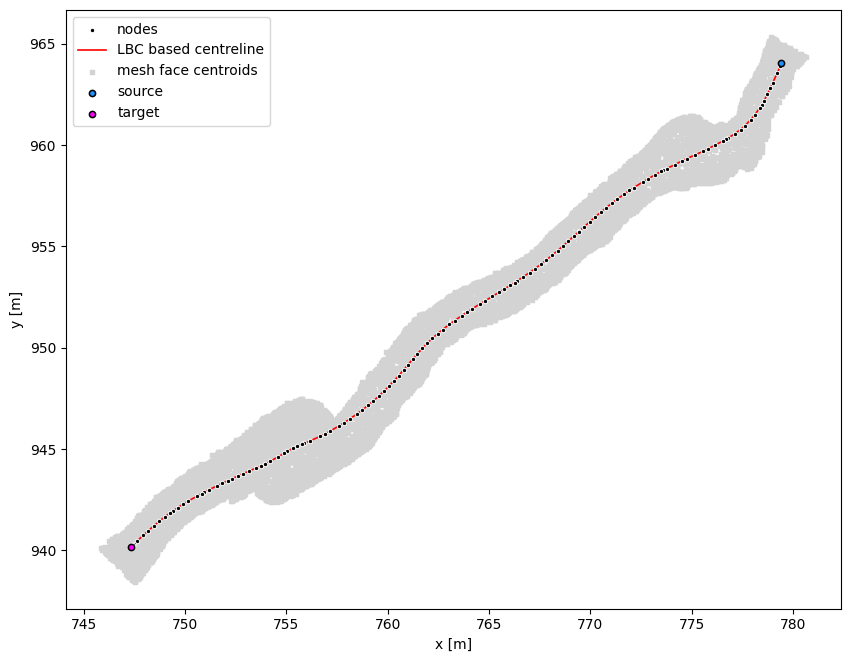

In [9]:
# start and end points. 
P1 = ct_nodes_lbc[0]
P2 = ct_nodes_lbc[-1]

fig, ax = plt.subplots(figsize = (10, 10))

ax.scatter(*ct_nodes_lbc[:, [0, 1]].T, **node_kwargs, label = "nodes")
ax.plot(*ct_nodes_lbc[:, [0, 1]].T, **ct_kwargs, label= "LBC based centreline")
ax.scatter(*data.centroids[::50, [0, 1]].T, **mesh_kwargs, label= "mesh face centroids")
ax.scatter(*P1[[0, 1]], **start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)
ax.set_aspect("equal")
ax.legend()
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
plt.show()

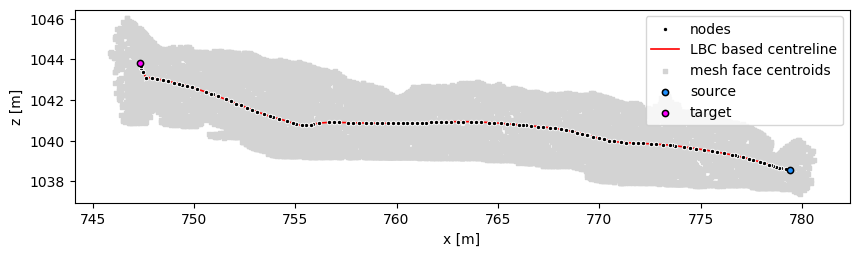

In [10]:
# start and end points. 
P1 = ct_nodes_lbc[0]
P2 = ct_nodes_lbc[-1]

fig, ax = plt.subplots(figsize = (10, 10))

ax.scatter(*ct_nodes_lbc[:, [0, 2]].T, **node_kwargs, label = "nodes")
ax.plot(*ct_nodes_lbc[:, [0, 2]].T, **ct_kwargs, label= "LBC based centreline")
ax.scatter(*data.centroids[::50, [0, 2]].T, **mesh_kwargs, label= "mesh face centroids")
ax.scatter(*P1[[0, 2]], **start_kwargs)
ax.scatter(*P2[[0, 2]], **end_kwargs)
ax.set_aspect("equal")
ax.legend()
ax.set_xlabel("x [m]")
ax.set_ylabel("z [m]")
plt.show()

we compute the normal looking vectors from the centreline by simple node position differencing.
For internal nodes: centered difference. 
For the extremities: forward and backward difference.

In [11]:
lbc_node_vectors = np.zeros((len(ct_nodes_lbc), 3))
lbc_node_vectors[0] = ct_nodes_lbc[1] - ct_nodes_lbc[0] # start node. 
lbc_node_vectors[-1] = ct_nodes_lbc[-1] - ct_nodes_lbc[-2] # end node. 
lbc_node_vectors[1:-1] = ct_nodes_lbc[2:] - ct_nodes_lbc[:-2] # internal nodes.

# for vertical sections we take only x-y coords.

lbc_node_vectors_v = lbc_node_vectors
lbc_node_vectors_v[:, 2] = 0
# we normalise to unit vectors.
lbc_node_vectors_v_n = lbc_node_vectors_v /  np.expand_dims(np.linalg.norm(lbc_node_vectors_v, axis = 1), -1)


## Computing sections
We read them from files if they already exist, otherwise compute them.

In [12]:
sections_3d = []
sections_2d = []

sections2d_fp = f"./temp/{ID}_{CONDUIT_NAME}/lbc/sections2d/"

if not isdir(sections2d_fp):
    makedirs(sections2d_fp)

sections3d_fp = f"./temp/{ID}_{CONDUIT_NAME}/lbc/sections3d/"

# save the 2d sections
if not isdir(sections3d_fp):
    makedirs(sections3d_fp)

keep_sections = True

d1 = np.array([0,1,0])

for k, (P, nP) in tqdm(enumerate(zip(ct_nodes_lbc, lbc_node_vectors_v_n)), total=len(lbc_node_vectors_v_n)):
    
    if exists(join(sections2d_fp, f"s2d_{k}.txt")) and keep_sections == True:
        # sections already exist.
        vertices_2d = np.loadtxt(join(sections2d_fp, f"s2d_{k}.txt"))
        vertices_3d = np.loadtxt(join(sections3d_fp, f"s3d_{k}.txt"))
    else:

        vertices_3d, _, _, _, _, _, _ = mesh_intersect(data, P, nP)
        pp = vertices_3d  - P
        R = vec2vec_rotation(nP, d1)
        pp_r = R @ pp.T

        vertices_2d = pp_r.T[:, [0, 2]]
        ## save if it does not exist yet. 
        np.savetxt(join(sections2d_fp, f"s2d_{k}.txt"), vertices_2d)
        np.savetxt(join(sections3d_fp, f"s3d_{k}.txt"), vertices_3d)


    sections_3d.append(vertices_3d)
    sections_2d.append(vertices_2d)

100%|██████████| 127/127 [00:10<00:00, 12.53it/s]


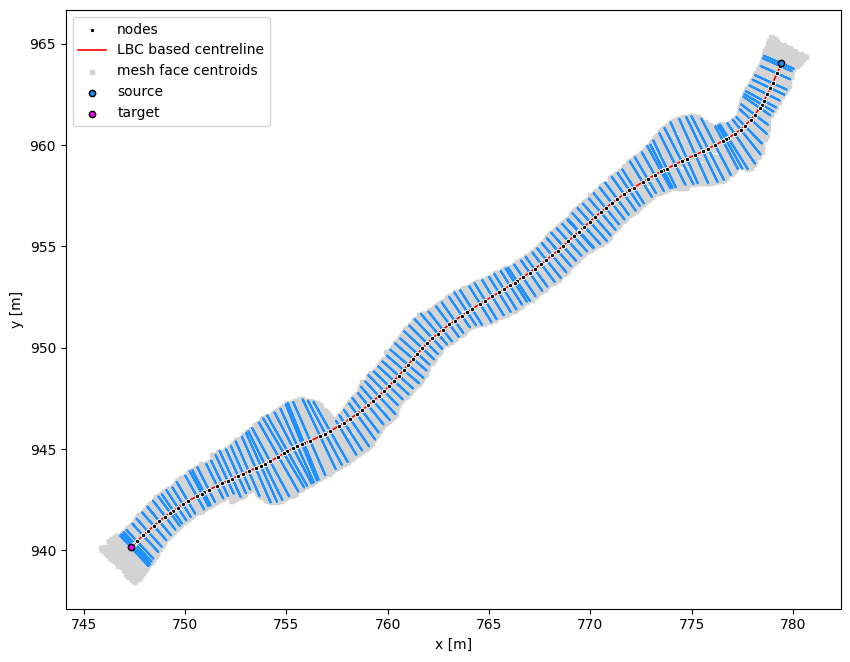

In [17]:
# start and end points. 
P1 = ct_nodes_lbc[0]
P2 = ct_nodes_lbc[-1]

fig, ax = plt.subplots(figsize = (10, 10))

ax.scatter(*ct_nodes_lbc[:, [0, 1]].T, **node_kwargs, label = "nodes")
ax.plot(*ct_nodes_lbc[:, [0, 1]].T, **ct_kwargs, label= "LBC based centreline")
ax.scatter(*data.centroids[::50, [0, 1]].T, **mesh_kwargs, label= "mesh face centroids")
ax.scatter(*P1[[0, 1]], **start_kwargs)
ax.scatter(*P2[[0, 1]], **end_kwargs)

for section_3d in sections_3d:
     ax.plot(*section_3d[:, [0,1]].T, color = "dodgerblue")

ax.set_aspect("equal")
ax.legend()
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
plt.show()

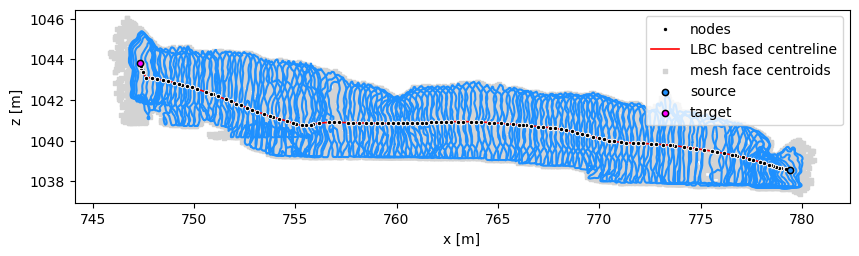

In [16]:
# start and end points. 
P1 = ct_nodes_lbc[0]
P2 = ct_nodes_lbc[-1]

fig, ax = plt.subplots(figsize = (10, 10))

ax.scatter(*ct_nodes_lbc[:, [0, 2]].T, **node_kwargs, label = "nodes")
ax.plot(*ct_nodes_lbc[:, [0, 2]].T, **ct_kwargs, label= "LBC based centreline")
ax.scatter(*data.centroids[::50, [0, 2]].T, **mesh_kwargs, label= "mesh face centroids")
ax.scatter(*P1[[0, 2]], **start_kwargs)
ax.scatter(*P2[[0, 2]], **end_kwargs)

for section_3d in sections_3d:
     ax.plot(*section_3d[:, [0,2]].T, color = "dodgerblue")

ax.set_aspect("equal")
ax.legend()
ax.set_xlabel("x [m]")
ax.set_ylabel("z [m]")
plt.show()

c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\pyvista\jupyter\notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (c:\Users\tangr\anaconda3\envs\pc-centreline\Lib\site-packages\trame\widgets\__init__.py)

Falling back to a static output.
  warnings.warn(


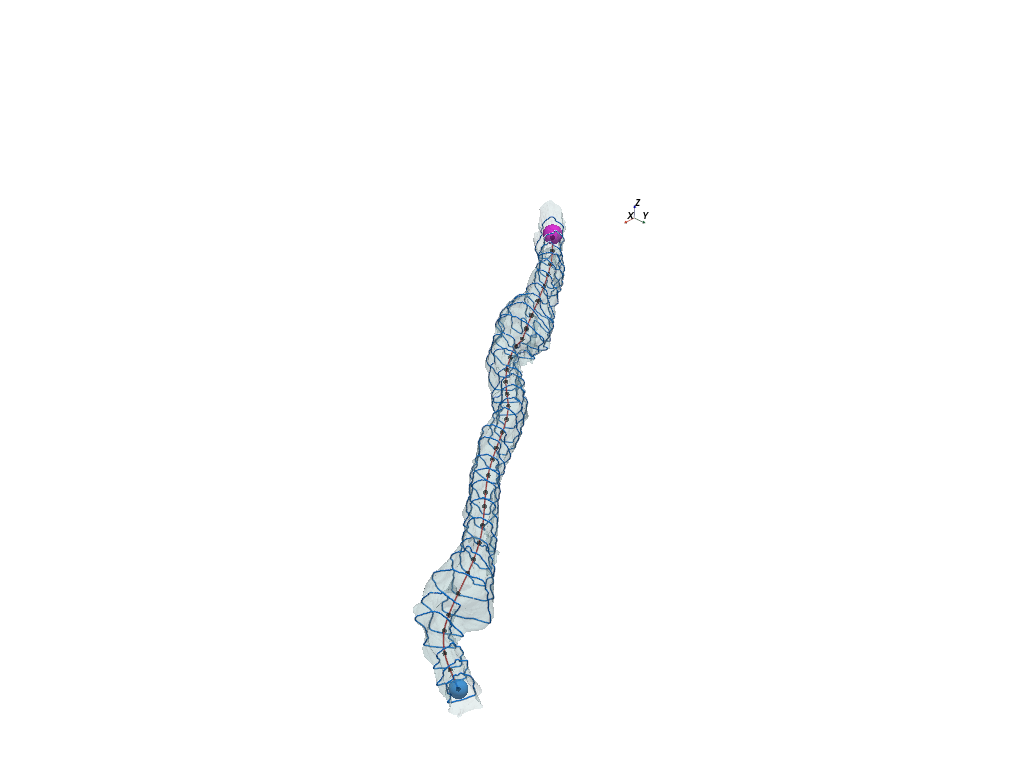

In [13]:

pl = pv.Plotter() 
# plot the mesh in 3d with pyvista.
pv_mesh = pv.read(file_format="stl", filename=mesh_fp)
_ = pl.add_mesh(pv_mesh, opacity = 0.25, label = f"mesh {CONDUIT_NAME}")

pv_spline_1 = pv.Spline(ct_nodes_lbc[::4, [0,1,2]], 500).tube(radius = 0.05)
_ = pl.add_mesh(pv_spline_1, color = "firebrick", label = "centreline")

_ = pl.add_points(ct_nodes_lbc[::4, [0,1,2]],
                render_points_as_spheres=True, 
                point_size = 5.,
                color = "k",
                opacity=0.75)

_ = pl.add_points(P1,
                render_points_as_spheres=True, 
                point_size = 20.,
                color = "dodgerblue",
                opacity=0.9, label = "source")
_ = pl.add_points(P2,
                render_points_as_spheres=True, 
                point_size = 20.,
                color = "fuchsia",
                opacity=0.9, label = "target")


for section_3d in sections_3d[::4]:
     pv_spline = pv.Spline(section_3d[:, [0,1,2]], 500).tube(radius = 0.05)
     _ = pl.add_mesh(pv_spline, color = "dodgerblue")    

axes = pv.AxesAssembly(position=pro_p["axesPosition"], label_size = 9)
_ = pl.add_actor(axes)
pv.set_plot_theme('document')

pl.save_graphic(f"./temp/{ID}_{CONDUIT_NAME}/lbc/{CONDUIT_NAME}_3d.pdf")
pl.show()

## Filling up a section 


In [18]:
from base.geometry import describe, compute_ngon_area, return_below_fill_height, get_full_area, compute_composite_dh, fit_ellipse, compute_ngon_perimeter, centre_of_gravity, compute_ngon_wetted_perimeter

In [19]:
def fill_section(section, fill_fractions, showfig = True, show_circle = False) -> tuple:

    areas = []
    wp = []

    filled_areas_by_fraction = []

    for fill_fraction in fill_fractions:
        filled_areas = return_below_fill_height(section, fill_fraction)
        area = get_full_area(section, fill_fraction)
        areas.append(area)
        
        thewp = 0
        if fill_fraction == 1:
            thewp= compute_ngon_perimeter(section)
        else:
            for filled_area in filled_areas:
                thewp+= compute_ngon_wetted_perimeter(filled_area)
        wp.append(thewp)
        filled_areas_by_fraction.append(filled_areas)

    if show_circle == True:
        cog = centre_of_gravity(section)
        circle_dh = 4* compute_ngon_area(section) / compute_ngon_perimeter(section)
        thetai = np.linspace(-np.pi, np.pi)

        dh_circle = np.vstack([cog[0]+circle_dh/2* np.cos(thetai), cog[1]+circle_dh/2* np.sin(thetai)]).T 
        dh_circle_areas = []
        wp_circle_dh = []

        for fill_fraction in fill_fractions:
            filled_areas = return_below_fill_height(dh_circle, fill_fraction)
            dh_circle_area = get_full_area(dh_circle, fill_fraction)
            dh_circle_areas.append(dh_circle_area)
            
            if len(filled_areas) == 0:
                thewp = 0

            elif fill_fraction ==  1:
                thewp = compute_ngon_perimeter(filled_areas[0])
            else: 
                thewp = compute_ngon_wetted_perimeter(filled_areas[0])
            
            wp_circle_dh.append(thewp)

    if showfig == True:
        fig, axes = plt.subplots(1, 3, figsize =(8, 4.5)) 
        
        for filled_areas in filled_areas_by_fraction:
            for filled_area in filled_areas:
                axes[0].fill(*filled_area.T, color = "dodgerblue", zorder = 10, alpha = 0.02);

        axes[0].plot(*dh_circle.T, color = "firebrick", zorder = 100)
        
        axes[1].plot(fill_fractions, dh_circle_areas, "-o", 
                    markersize = 3, 
                    color = "firebrick", label ="Hydraulic diameter disk")
        axes[2].plot(fill_fractions, wp_circle_dh, "-o", 
                    markersize = 3, 
                    color = "firebrick", label = "Hydraulic diameter disk")

    
        axes[0].fill(*section.T, color = "white", edgecolor="dodgerblue")
        axes[0].set_aspect("equal")
        axes[0].set_xlabel("x [m]")
        axes[0].set_ylabel("y [m]")

        axes[1].plot(fill_fractions[:-1], areas[:-1], "-o", markersize = 3, label = "original section", color ="dodgerblue")

        axes[1].set_xlabel("fill height fraction []")
        axes[1].set_ylabel("area [m$^2$]")

        axes[2].plot(fill_fractions, wp, "-o", markersize = 3, label = "original section ", color = "dodgerblue")
        axes[2].set_xlabel("fill height fraction []")
        axes[2].set_ylabel("wetted perimeter [m]")

        axes[1].legend(fontsize = 8, loc = "upper left")
        axes[2].legend(fontsize = 8, loc = "upper left")

        plt.tight_layout()
        plt.show();
    return areas, wp

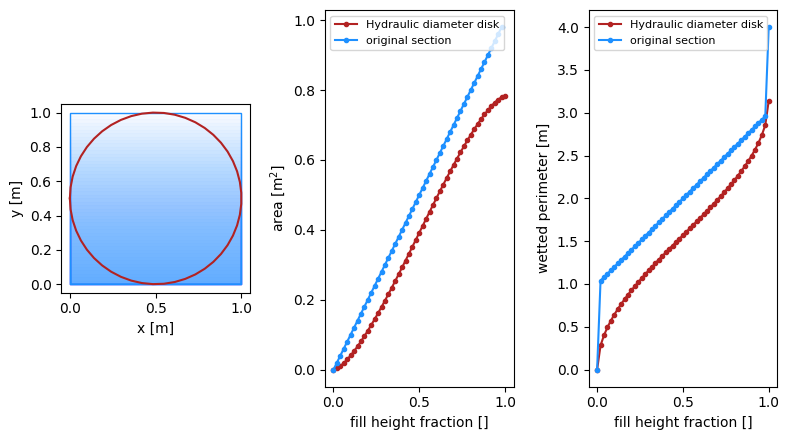

In [20]:
square = np.array([[0,0], [1, 0.],[1,1.],[0,1]])
fill_fractions = np.arange(0,1.02, 0.02)

_ = fill_section(square, fill_fractions, showfig=True, show_circle=True)

## question should be: 
by fill height? 

In [21]:
def convert_heights_to_fractions(heights, maxheight):
    return 1 - np.maximum(maxheight - heights, 0) / maxheight

In [22]:
global_maxh = 5
dy = 0.1
fill_heights = np.arange(0, global_maxh, dy)

In [24]:


filled_areas = np.zeros((len(fill_heights), len(sections_2d) ))
filled_wp = np.zeros((len(fill_heights), len(sections_2d) ))
maxhi = []

for k, section_2d in tqdm(enumerate(sections_2d), total = len(sections_2d)):
    maxh = np.max(section_2d[:, 1]) - np.min(section_2d[:, 1])
    maxhi.append(maxh)
    fill_fractions = convert_heights_to_fractions(fill_heights, maxh)

    try: 
        areas, wp = fill_section(section_2d, fill_fractions, showfig=False, show_circle=True)
        filled_areas[:, k] = areas
        filled_wp[:, k] = wp
    except ValueError:
        pass


100%|██████████| 127/127 [00:10<00:00, 11.94it/s]


### plot a summary of the filling up state functions. 

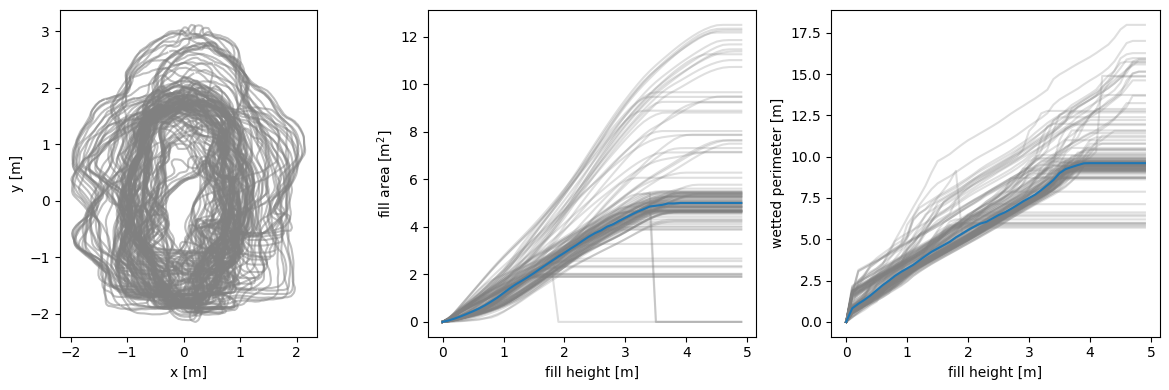

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# plot all the 2d sections. 
for section_2d in sections_2d:
    axes[0].plot(*section_2d.T, color = "grey", alpha = 0.5)
axes[0].set_aspect("equal")
axes[0].set_xlabel("x [m]")
axes[0].set_ylabel("y [m]")

for k in filled_areas.T:
    axes[1].plot(fill_heights, k, color = "grey", alpha = 0.25)
axes[1].plot(fill_heights, np.median(filled_areas, axis =1))
axes[1].set_xlabel("fill height [m]")
axes[1].set_ylabel("fill area [m$^2$]")

for k in filled_wp.T:
    axes[2].plot(fill_heights, k, color = "grey", alpha = 0.25)
axes[2].plot(fill_heights, np.median(filled_wp, axis =1))
axes[2].set_xlabel("fill height [m]")
axes[2].set_ylabel("wetted perimeter [m]")

plt.tight_layout()
plt.show()

In [29]:
from base.utils import equivalent_dh

## behaviour of equivalent circle. 

In [30]:
dhi = np.array([describe(section_2d)["hydraulic_diameter"] for section_2d in sections_2d])
li = np.linalg.norm(lbc_node_vectors, axis = 1)
dh_eq = equivalent_dh(dhi, li)

# equivalent circle 
thetai = np.linspace(-np.pi, np.pi)
eq_circle = np.vstack([np.cos(thetai)*dh_eq/2, np.sin(thetai)*dh_eq/2]).T
eq_fill_fractions = convert_heights_to_fractions(fill_heights, dh_eq)
area_eq_circle, wp_eq_circle = fill_section(eq_circle, eq_fill_fractions, showfig=False, show_circle=True)


Mean ellipse.

In [31]:
rots = [describe(section2d)["ellipse_rotation"] for section2d in sections_2d]
axes = [describe(section2d)["ellipse_eigenvalues"] for section2d in sections_2d]
mean_rot = np.mean(rots)
mean_axes = np.mean(np.array(axes), axis =0)

mean_ellipse = np.vstack([np.cos(thetai)*mean_axes[0], np.sin(thetai)*mean_axes[1]]).T
R = np.array([[np.cos(mean_rot), -np.sin(mean_rot)],[np.sin(mean_rot), np.cos(mean_rot)]])


In [32]:
mean_ellipse_rotated = mean_ellipse @ R
ellipse_maxh = np.max(mean_ellipse_rotated[:, 1]) - np.min(mean_ellipse_rotated[:, 1]) 
ellipse_fill_fractions = convert_heights_to_fractions(fill_heights, ellipse_maxh)
area_ellipse, wp_ellipse = fill_section(mean_ellipse_rotated, ellipse_fill_fractions, showfig=False, show_circle=True)


The bottle neck is possibly the section with the smallest hydraulic diameter. 

In [33]:

idx_min = np.argmin(dhi)
smallest_dh = sections_2d[idx_min]
smallest_dh_maxh = np.max(smallest_dh[:, 1]) - np.min(smallest_dh[:, 0])
smallest_dh_fill_fractions = convert_heights_to_fractions(fill_heights, smallest_dh_maxh)
smallest_dh_areas, smallest_dh_wp = fill_section(smallest_dh, smallest_dh_fill_fractions, showfig=False)

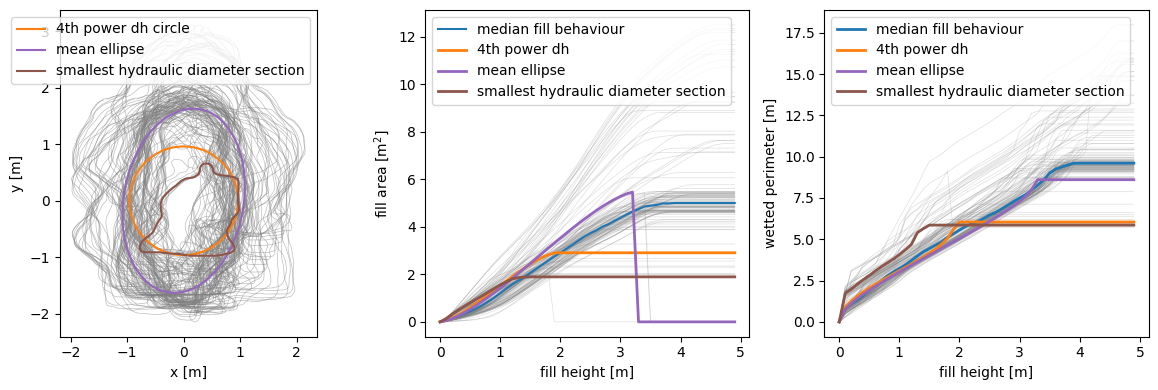

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# plot all the 2d sections. 
for section_2d in sections_2d:
    axes[0].plot(*section_2d.T, color = "grey", alpha = 0.5, lw = 0.5)
axes[0].set_aspect("equal")
axes[0].set_xlabel("x [m]")
axes[0].set_ylabel("y [m]")

axes[0].plot(*eq_circle.T, color = "C1", label ="4th power dh circle")
axes[0].plot(*(mean_ellipse @ R).T, color = "C4", label = "mean ellipse")
axes[0].plot(*smallest_dh.T, color = "C5", label = "smallest hydraulic diameter section")
axes[0].legend()

for k in filled_areas.T:
    axes[1].plot(fill_heights, k, color = "grey", alpha = 0.25, lw = 0.5)
axes[1].plot(fill_heights, np.median(filled_areas, axis =1), label = "median fill behaviour")
axes[1].set_xlabel("fill height [m]")
axes[1].set_ylabel("fill area [m$^2$]")
axes[1].plot(fill_heights, area_eq_circle, color = "C1", label = "4th power dh", lw = 2)
axes[1].plot(fill_heights, area_ellipse, color = "C4", label = "mean ellipse", lw = 2)
axes[1].plot(fill_heights, smallest_dh_areas, label = "smallest hydraulic diameter section", lw =2, color = "C5")


axes[1].legend()

for k in filled_wp.T:
    axes[2].plot(fill_heights, k, color = "grey", alpha = 0.25, lw = 0.5)
axes[2].plot(fill_heights, np.median(filled_wp, axis =1), label = "median fill behaviour", lw = 2)
axes[2].set_xlabel("fill height [m]")
axes[2].set_ylabel("wetted perimeter [m]")
axes[2].plot(fill_heights, wp_eq_circle, color = "C1", label = "4th power dh", lw = 2)
axes[2].plot(fill_heights, wp_ellipse, color = "C4", label = "mean ellipse", lw = 2)
axes[2].plot(fill_heights, smallest_dh_wp, label = "smallest hydraulic diameter section", lw =2, color = "C5")

axes[2].legend()

plt.tight_layout()
plt.show()


## filling up other sections

In [49]:
fill_fractions = np.arange(0,1,0.02)

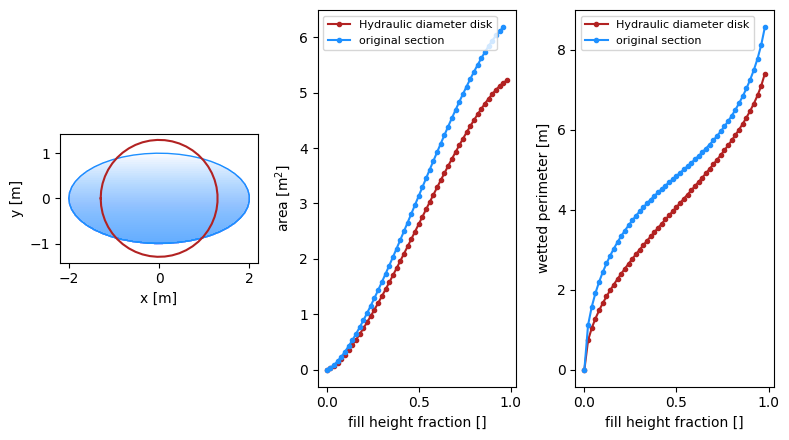

In [50]:
# ellipse 
thetai = np.linspace(-np.pi, np.pi)
ellipse = np.vstack([2*np.cos(thetai), np.sin(thetai)]).T
_ = fill_section(ellipse, fill_fractions,  showfig=True ,show_circle=True)

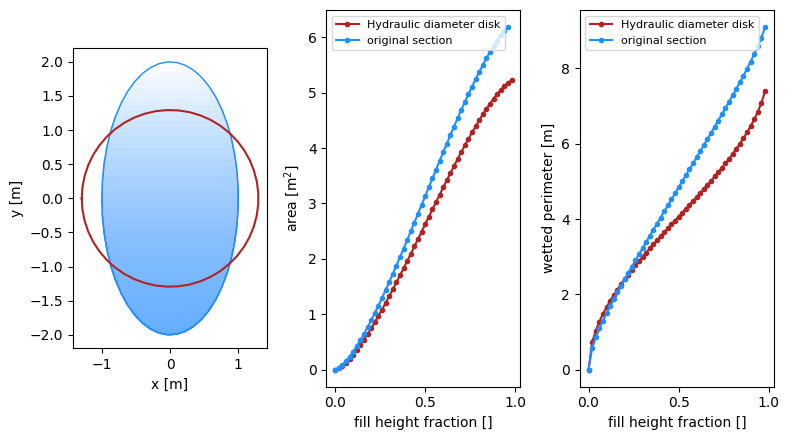

In [51]:
# ellipse 
thetai = np.linspace(-np.pi, np.pi)
ellipse = np.vstack([np.cos(thetai), 2*np.sin(thetai)]).T
_ = fill_section(ellipse, fill_fractions,  showfig=True ,show_circle=True)

In [52]:
def deepen_ellipse(r, k, d, w):
    thetai = np.linspace(0, 2*np.pi, 100)
    xi = r*k*np.cos(thetai)
    yi = r*np.sin(thetai)

    within_width = np.logical_and(thetai  > np.arccos(1/2*w/(r*k))+np.pi, thetai < np.arccos(-1/2*w/(r*k))+np.pi)

    yi[within_width] = -r-d

    return np.vstack([xi, yi]).T

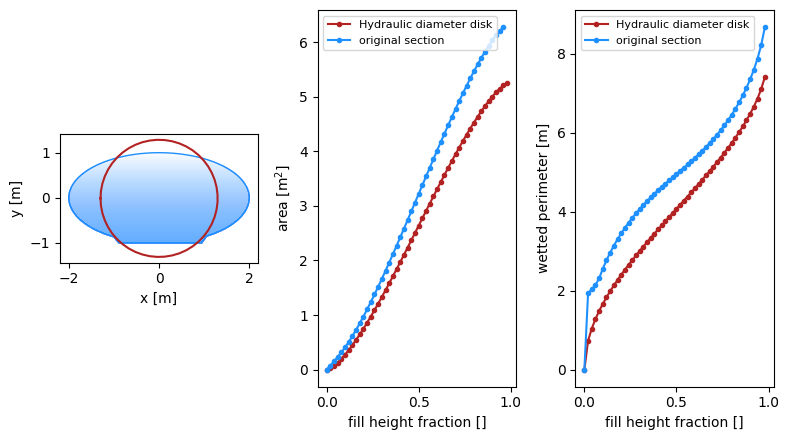

In [53]:
ellipse_with_small_trench = deepen_ellipse(1, 2, 0., 2)
_ = fill_section(ellipse_with_small_trench, fill_fractions,  showfig=True ,show_circle=True)

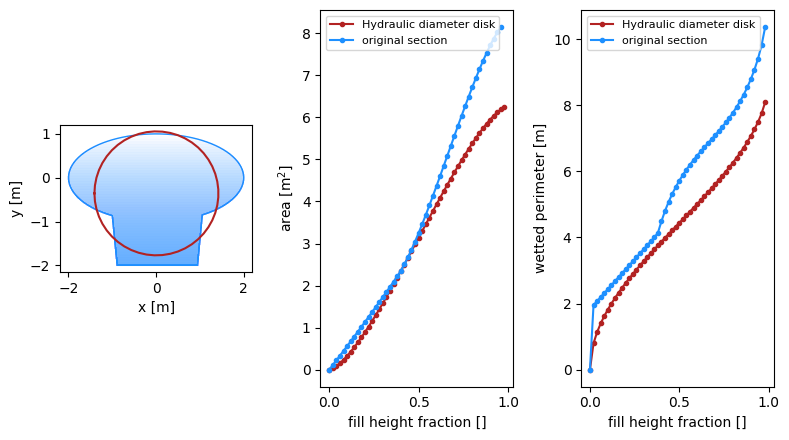

In [54]:
ellipse_with_small_trench = deepen_ellipse(1, 2, 1, 2)
_ = fill_section(ellipse_with_small_trench, fill_fractions,  showfig=True ,show_circle=True)

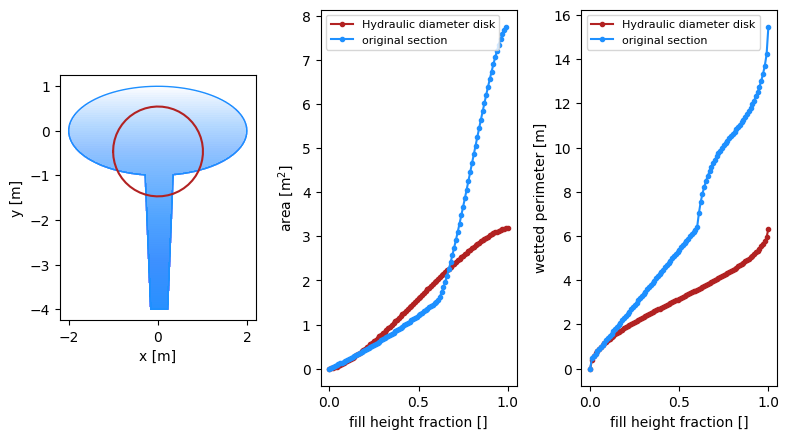

In [73]:
ellipse_with_small_trench = deepen_ellipse(1, 2, 3, 0.5)
fill_fractions = np.linspace(0, 1, 101)
out = fill_section(ellipse_with_small_trench, fill_fractions,  showfig=True ,show_circle=True)

In [74]:
areas = np.array(out[0])
wp = np.array(out[1])


state_func_fp = f"./temp/state_function.txt"
np.savetxt(state_func_fp, np.vstack([fill_fractions, areas, wp]).T, fmt = "%.5e")
shape_fp = f"./temp/deep_trench_polyline.txt"
np.savetxt(shape_fp, ellipse_with_small_trench, fmt= "%.5e")

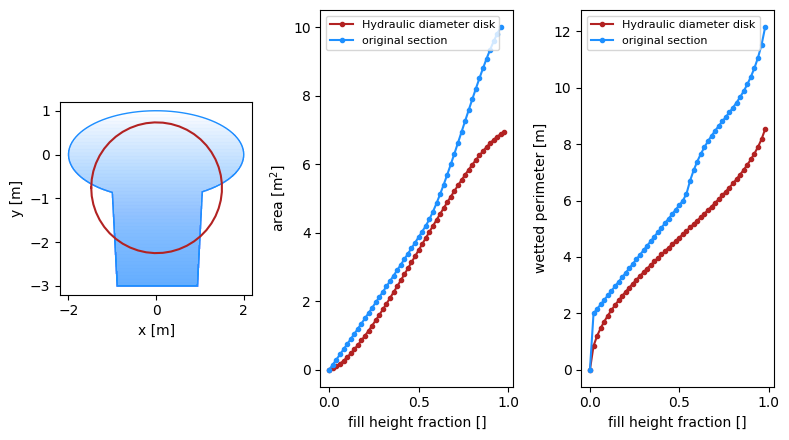

In [ ]:
ellipse_with_small_trench = deepen_ellipse(1, 2, 2, 2)
_ = fill_section(ellipse_with_small_trench, fill_fractions,  showfig=True ,show_circle=True)



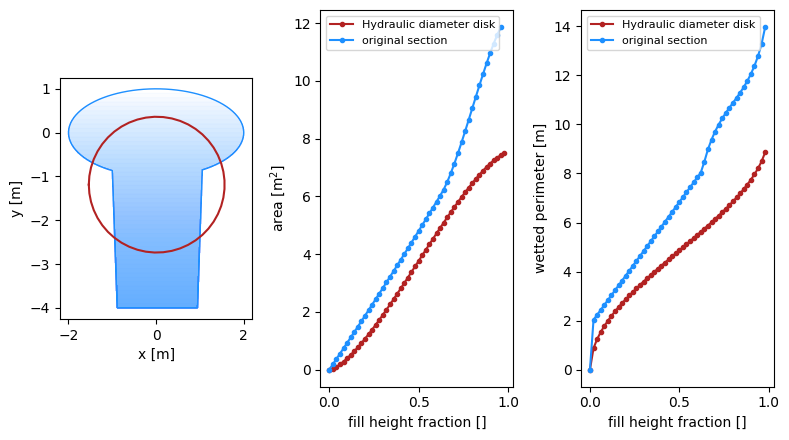

In [57]:
ellipse_with_small_trench = deepen_ellipse(1, 2, 3, 2)
_ = fill_section(ellipse_with_small_trench, fill_fractions,  showfig=True ,show_circle=True)

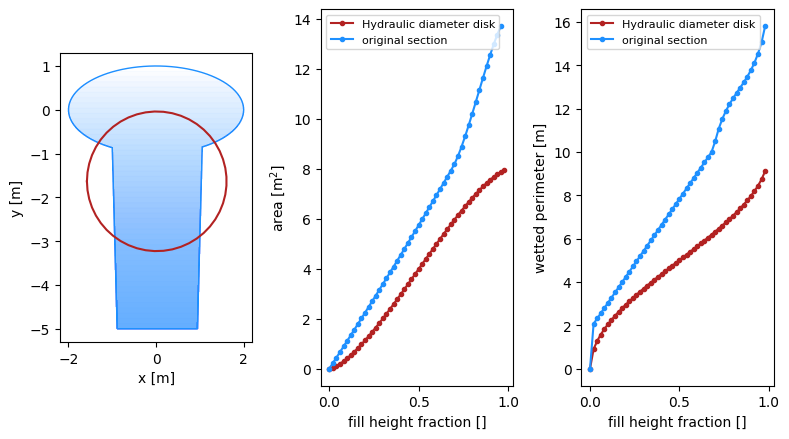

In [58]:
ellipse_with_small_trench = deepen_ellipse(1, 2, 4, 2)
_ = fill_section(ellipse_with_small_trench, fill_fractions,  showfig=True ,show_circle=True)

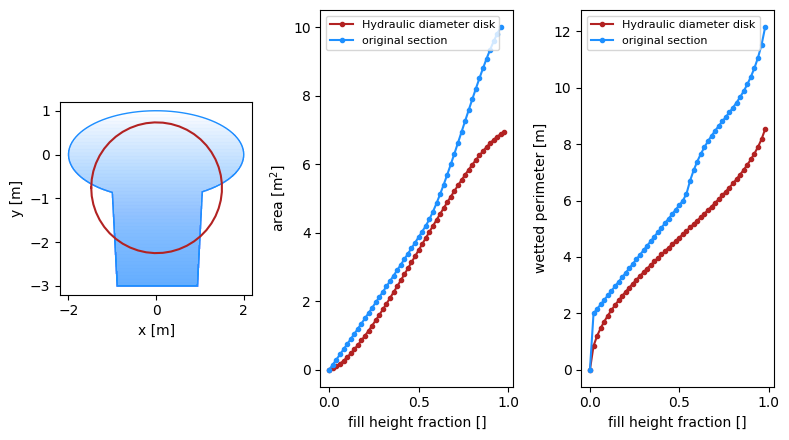

In [59]:
ellipse_with_small_trench = deepen_ellipse(1, 2, 2, 2)
_ = fill_section(ellipse_with_small_trench, fill_fractions,  showfig=True ,show_circle=True)

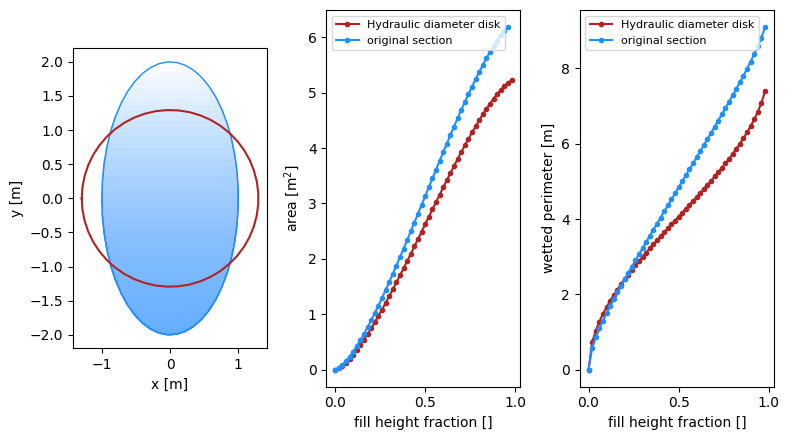

In [60]:
# ellipse 
thetai = np.linspace(-np.pi, np.pi)
ellipse = np.vstack([np.cos(thetai), 2*np.sin(thetai)]).T
_ = fill_section(ellipse, fill_fractions,  showfig=True ,show_circle=True)

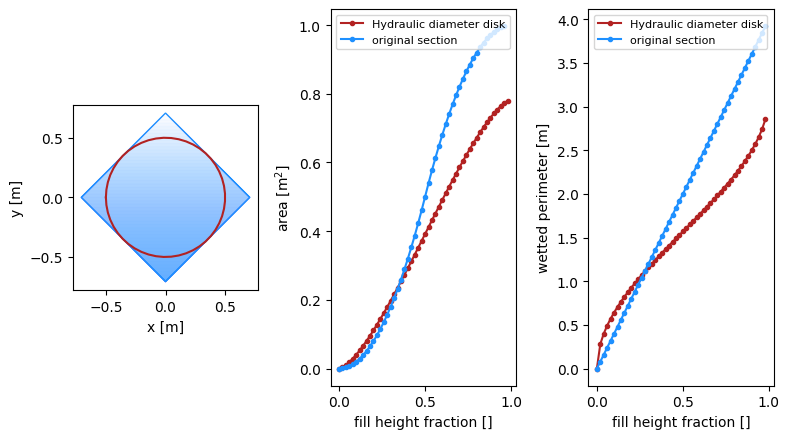

In [61]:
square2 = np.array([[0,-1/np.sqrt(2)], [1/np.sqrt(2), 0.],[0,1/np.sqrt(2)],[-1/np.sqrt(2),0]])
_ = fill_section(square2, fill_fractions,  showfig=True ,show_circle=True)

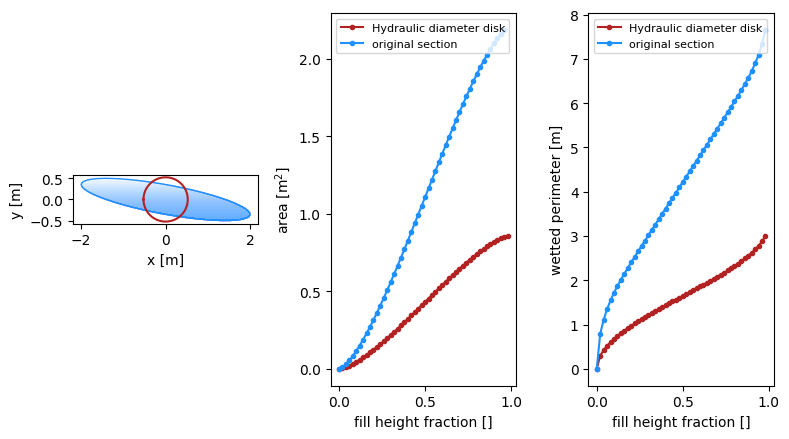

In [62]:
section_ellipse = np.array([2*np.cos(np.pi / 4 + np.linspace(-np.pi, np.pi)), 1/2*np.sin(np.linspace(-np.pi, np.pi))]).T
_ = fill_section(section_ellipse, fill_fractions,  showfig=True ,show_circle=True)

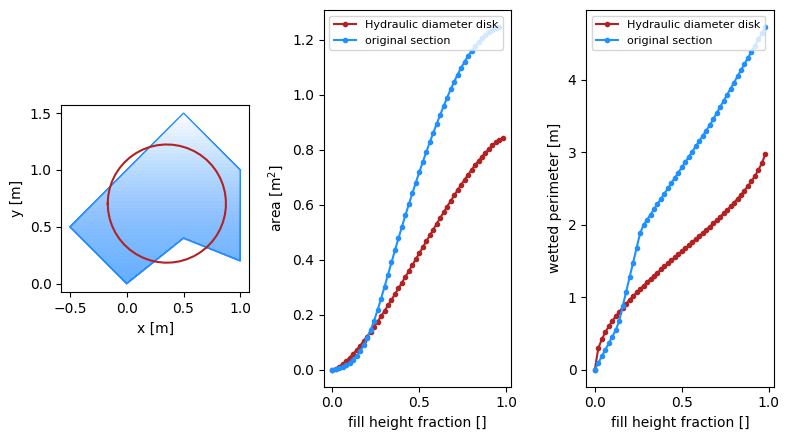

In [63]:
section = np.array([[0,0], [0.5, 0.4],[1,0.2],[1,1],[0.5,1.5],[0, 1],[-0.5, 0.5]])

_ = fill_section(section, fill_fractions,  showfig=True ,show_circle=True)